# Fitness convergence

The main run keeps only final results (`results/fewshot.csv`); the GRAPE
logbook is discarded after each search. `harvest_convergence.py` re-runs
chosen cells with the exact cell construction, subsets, grammar and search
seeds of the main run and records the minimum fitness per generation;
`convergence_figure.py` plots the median best-so-far fitness with the
interquartile band over the ten draws.

Harvested cells are skipped on re-run, so interrupting the harvest and
re-running it later loses nothing.

In [1]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd()
assert (ROOT / "geprior").exists(), "run this notebook from the project root"
sys.path.insert(0, str(ROOT))

from geprior import config, tabular
print(config.summary())

pop=200 gens=40 hof=20 fitness=auc shots=(4, 8, 16, 32, 64)+full draws=10 methods=('none', 'corr', 'mi', 'pca', 'rf', 'llm') ensemble=9 scaler=shots full_cap=1000 backend=cached


## Choice of cells

Fitness is 1 minus the training ROC-AUC on the k labelled rows, so at
k <= 16 most runs reach a perfect training AUC and the curve floors at zero,
which a log axis cannot show. k = 64 is the largest labelling budget of the
primary design and stays clear of the floor on most datasets.

In [2]:
DATASETS = list(tabular.FEATLLM_DATASETS)   # or a subset, e.g. ["heart"]
SHOT = "64"                                 # one of 4, 8, 16, 32, 64, full
WORKERS = max(2, (os.cpu_count() or 2) - 1)

## Harvest

770 GE cells (11 datasets x 7 methods x 10 draws); Car costs the most (four
one-versus-rest rules per cell). Roughly half an hour on two cores. Writes
`results/convergence/<dataset>__shot<shot>.csv`, one row per
(method, seed, generation).

In [3]:
for dataset in DATASETS:
    !"{sys.executable}" harvest_convergence.py {dataset} --shot {SHOT} --workers {WORKERS}

nothing to do; results/convergence/adult__shot64.csv is complete


nothing to do; results/convergence/bank__shot64.csv is complete


nothing to do; results/convergence/blood__shot64.csv is complete


nothing to do; results/convergence/car__shot64.csv is complete


nothing to do; results/convergence/communities__shot64.csv is complete


nothing to do; results/convergence/credit_g__shot64.csv is complete


nothing to do; results/convergence/diabetes__shot64.csv is complete


nothing to do; results/convergence/heart__shot64.csv is complete


nothing to do; results/convergence/myocardial__shot64.csv is complete


nothing to do; results/convergence/cultivars__shot64.csv is complete


nothing to do; results/convergence/nhanes__shot64.csv is complete


## Consistency check

Every harvested cell must end where the main run ended: final best-so-far
fitness equal to 1 minus `train_roc_auc` in `results/fewshot.csv`.

In [4]:
import pandas as pd

camp = pd.read_csv("results/fewshot.csv", dtype={"shot": str})
for dataset in DATASETS:
    conv = pd.read_csv(f"results/convergence/{dataset}__shot{SHOT}.csv", dtype={"shot": str})
    last = conv[conv.gen == conv.gen.max()].merge(camp, on=["dataset", "shot", "control", "seed"])
    agree = int(((last.best_so_far - (1 - last.train_roc_auc)).abs() < 1e-12).sum())
    print(f"  {dataset}: {agree}/{len(last)} cells reproduce the main run")

  adult: 70/70 cells reproduce the main run
  bank: 70/70 cells reproduce the main run
  blood: 70/70 cells reproduce the main run


  car: 70/70 cells reproduce the main run


  communities: 70/70 cells reproduce the main run
  credit_g: 70/70 cells reproduce the main run
  diabetes: 70/70 cells reproduce the main run
  heart: 70/70 cells reproduce the main run
  myocardial: 70/70 cells reproduce the main run
  cultivars: 70/70 cells reproduce the main run
  nhanes: 70/70 cells reproduce the main run


## Figures

Per dataset: the five-method figure and the `_all` variant with the
all-features baseline, PNG and PDF under `figures/`. On the `_all` variant
the all-features baseline tends to reach the lowest training fitness
because the full feature set on k rows leaves the most room to overfit; the
test-AUC figures show the opposite ordering.

In [5]:
for dataset in DATASETS:
    !"{sys.executable}" convergence_figure.py {dataset} --shot {SHOT}

  figures/fig_convergence_adult_shot_64.png


  figures/fig_convergence_adult_shot_64_all.png


  figures/fig_convergence_bank_shot_64.png


  figures/fig_convergence_bank_shot_64_all.png


  figures/fig_convergence_blood_shot_64.png


  figures/fig_convergence_blood_shot_64_all.png


... (12 outputs left out)

  figures/fig_convergence_cultivars_shot_64.png


  figures/fig_convergence_cultivars_shot_64_all.png


  figures/fig_convergence_nhanes_shot_64.png


  figures/fig_convergence_nhanes_shot_64_all.png


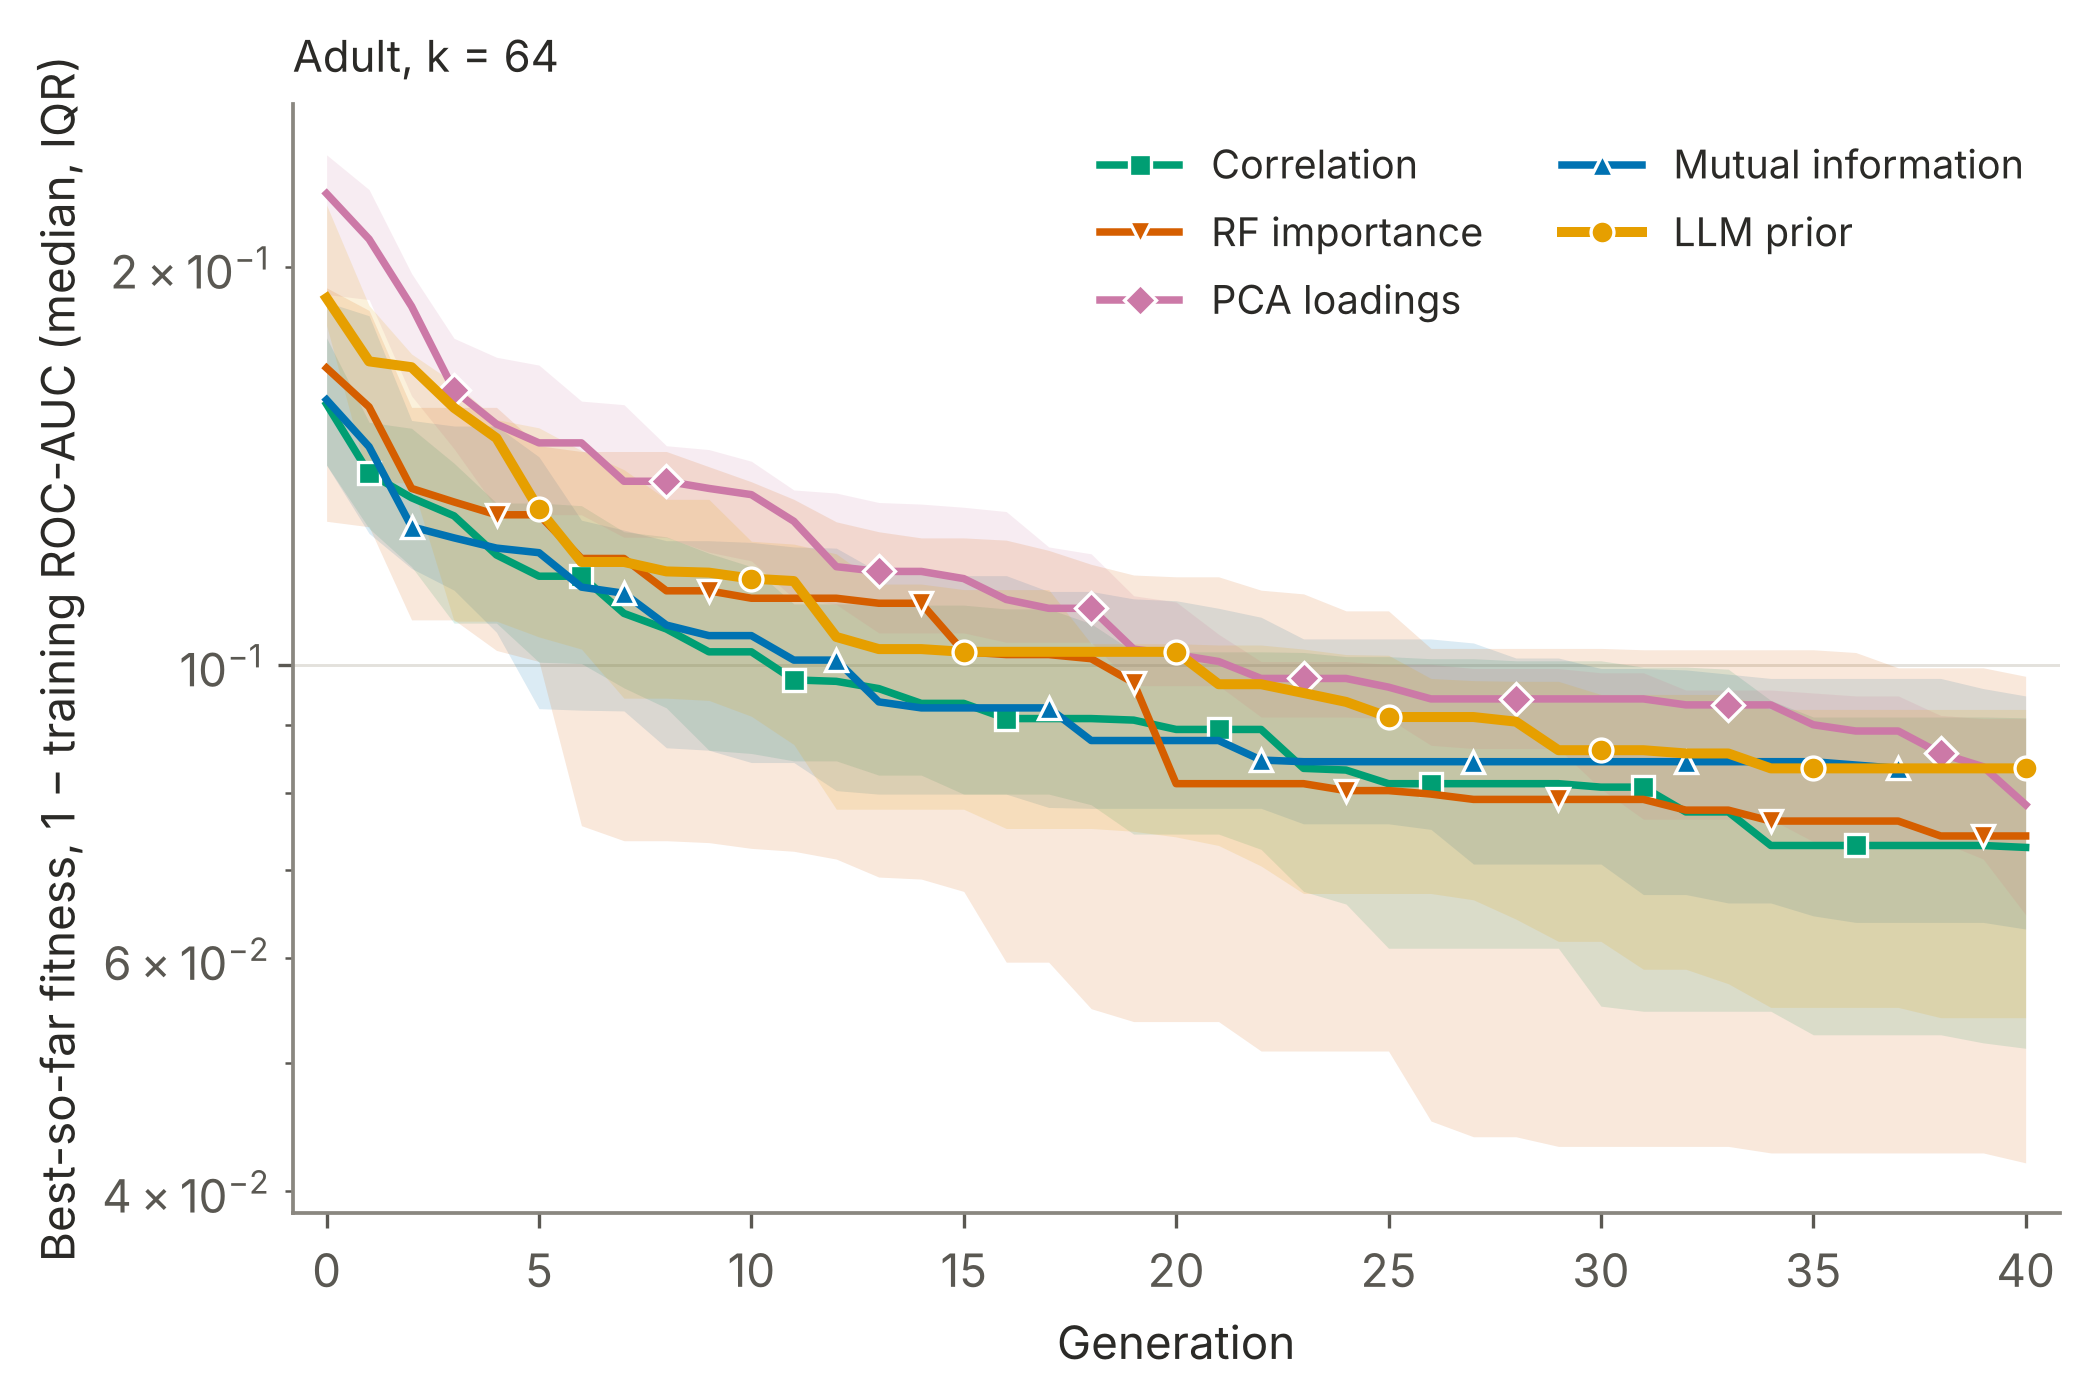

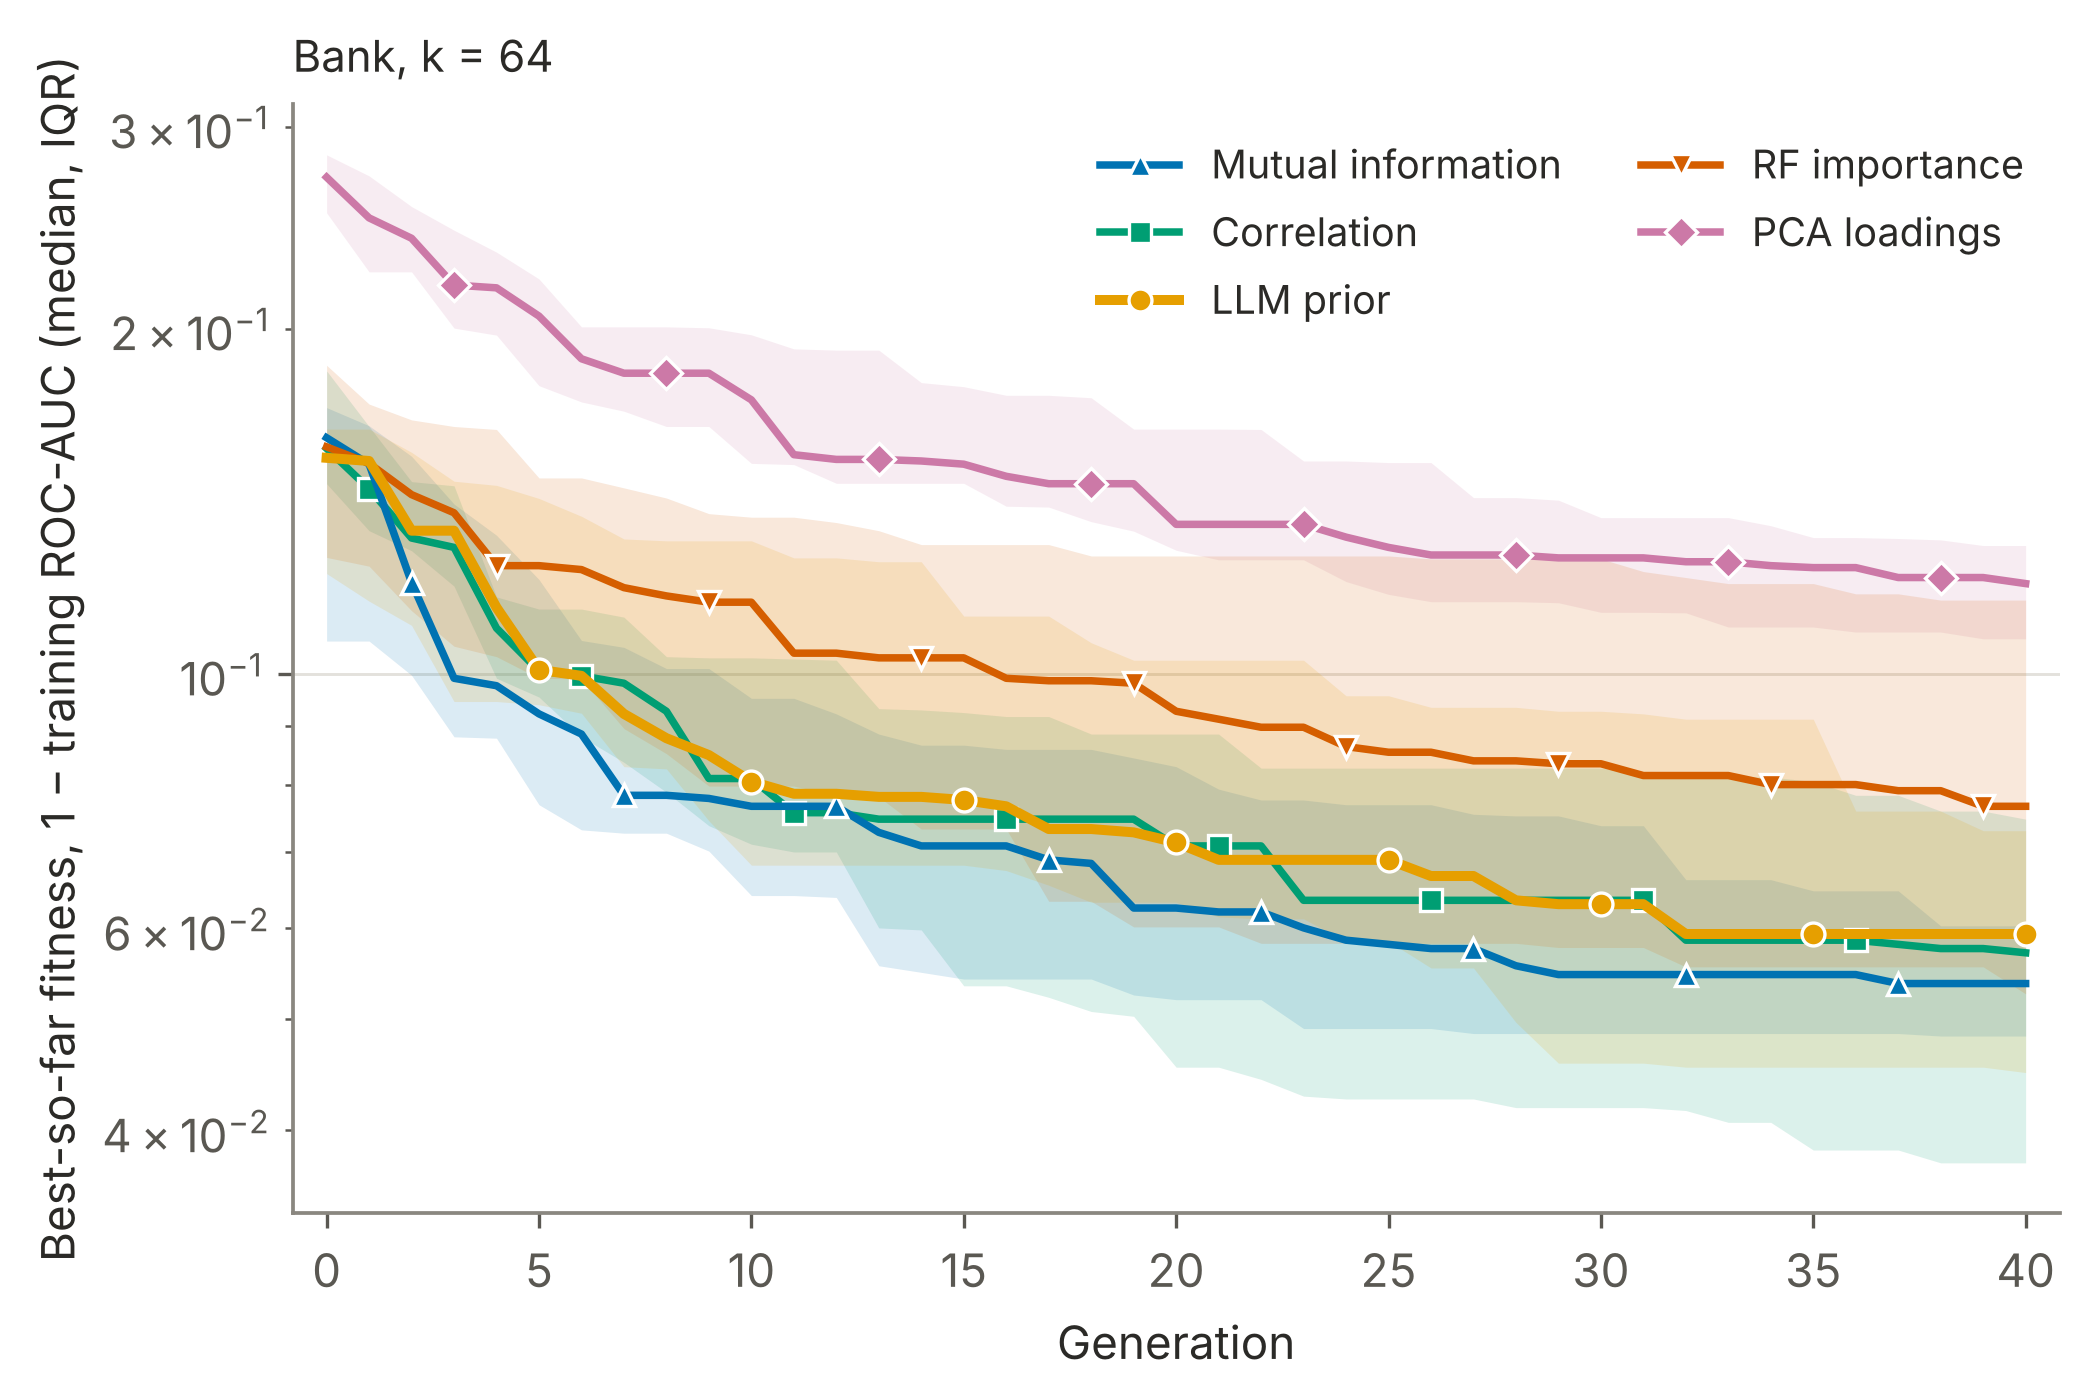

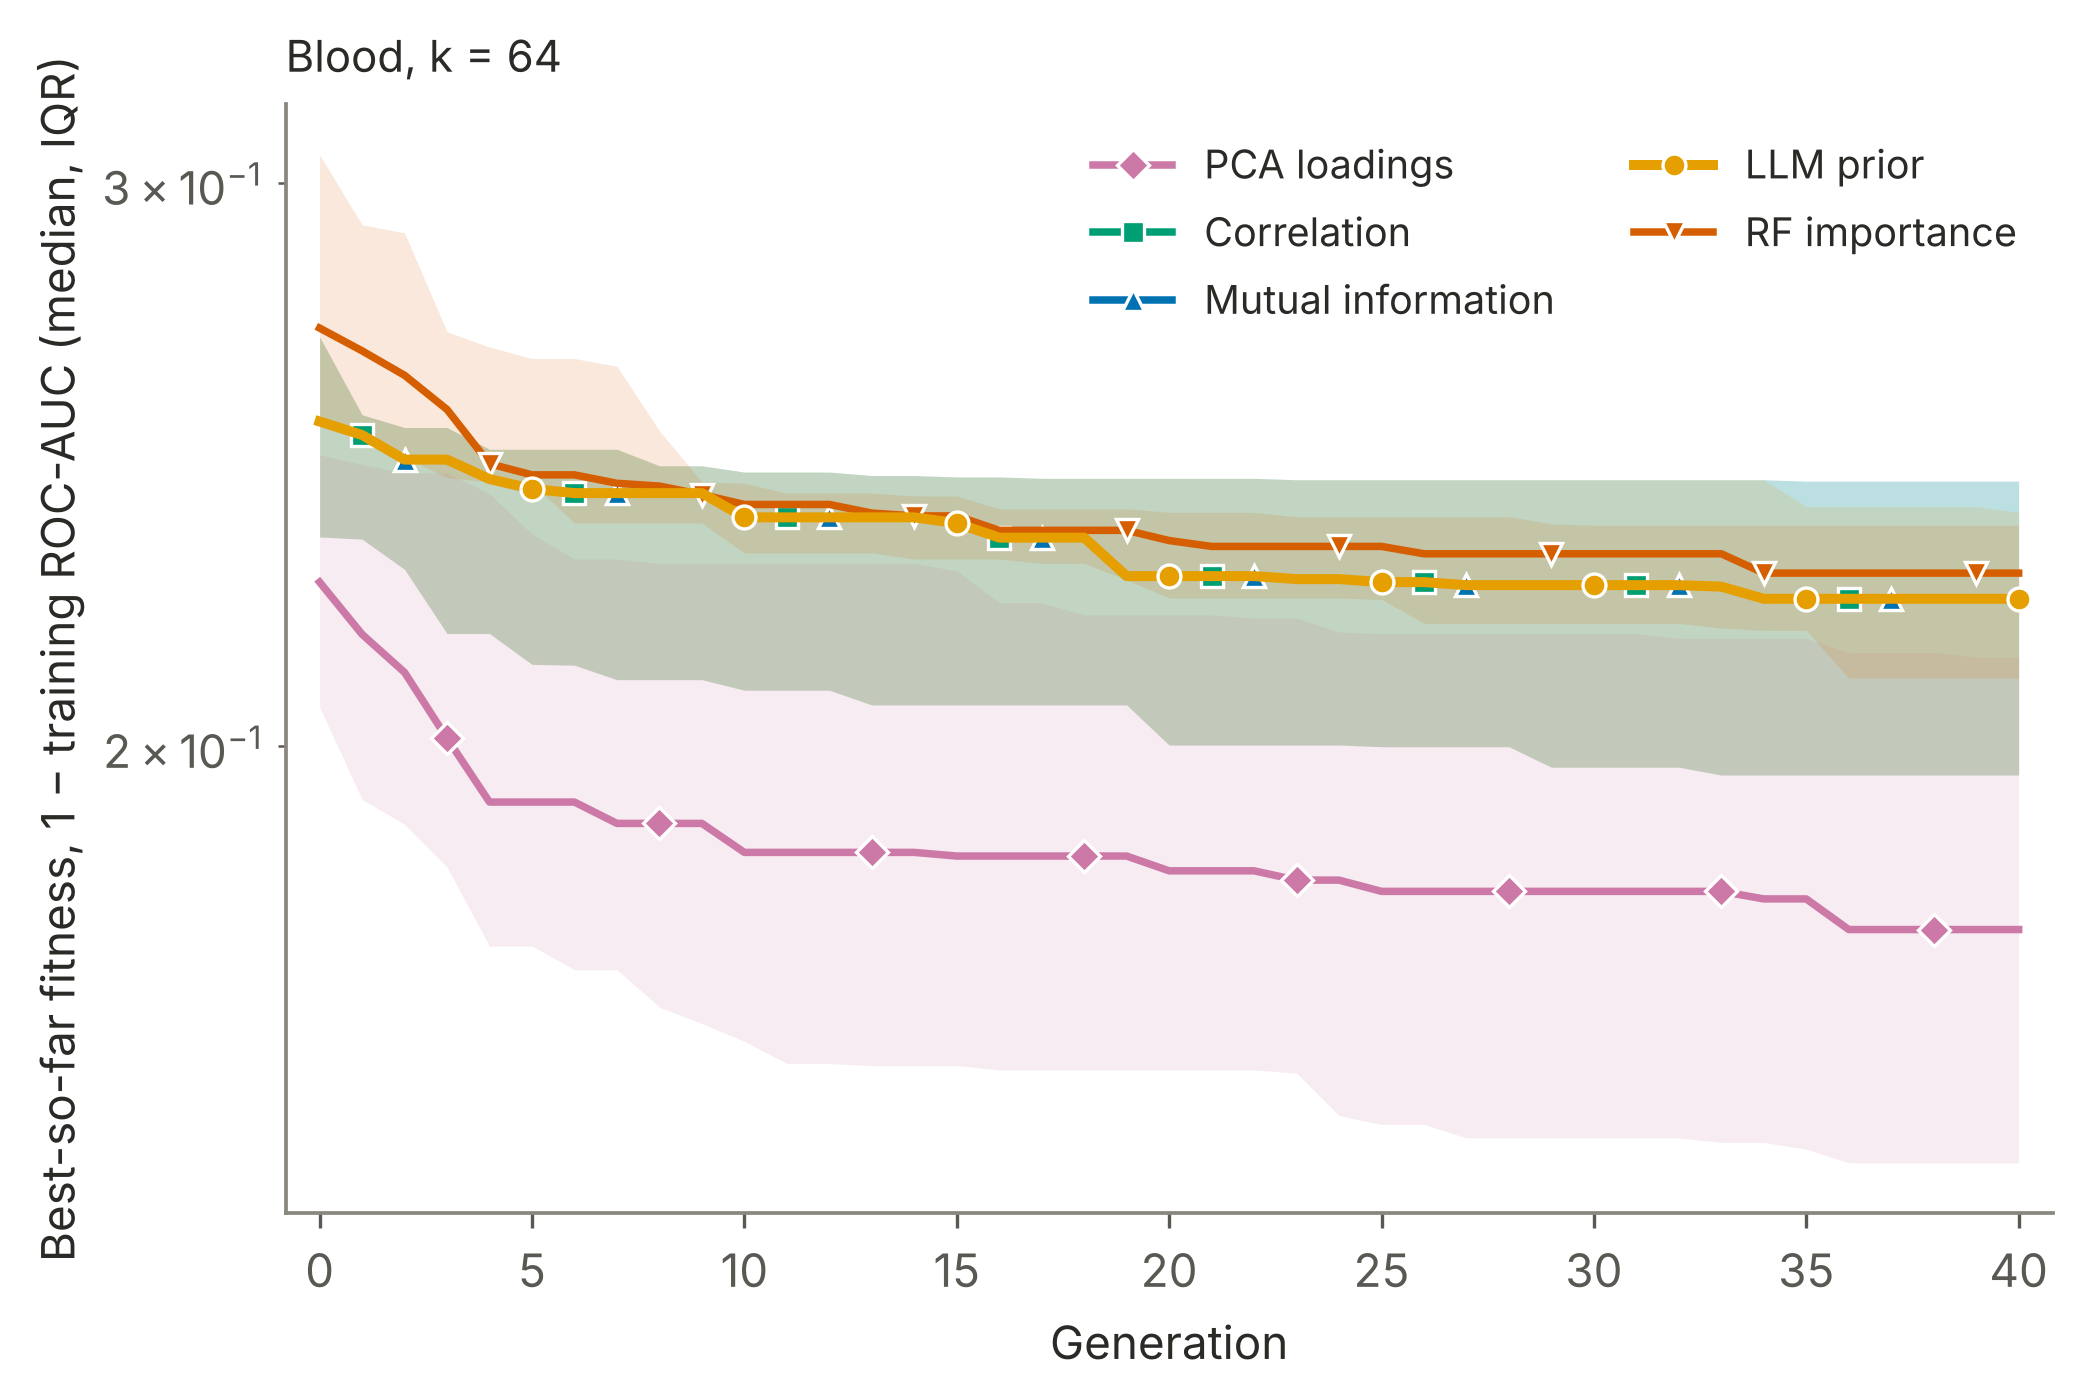

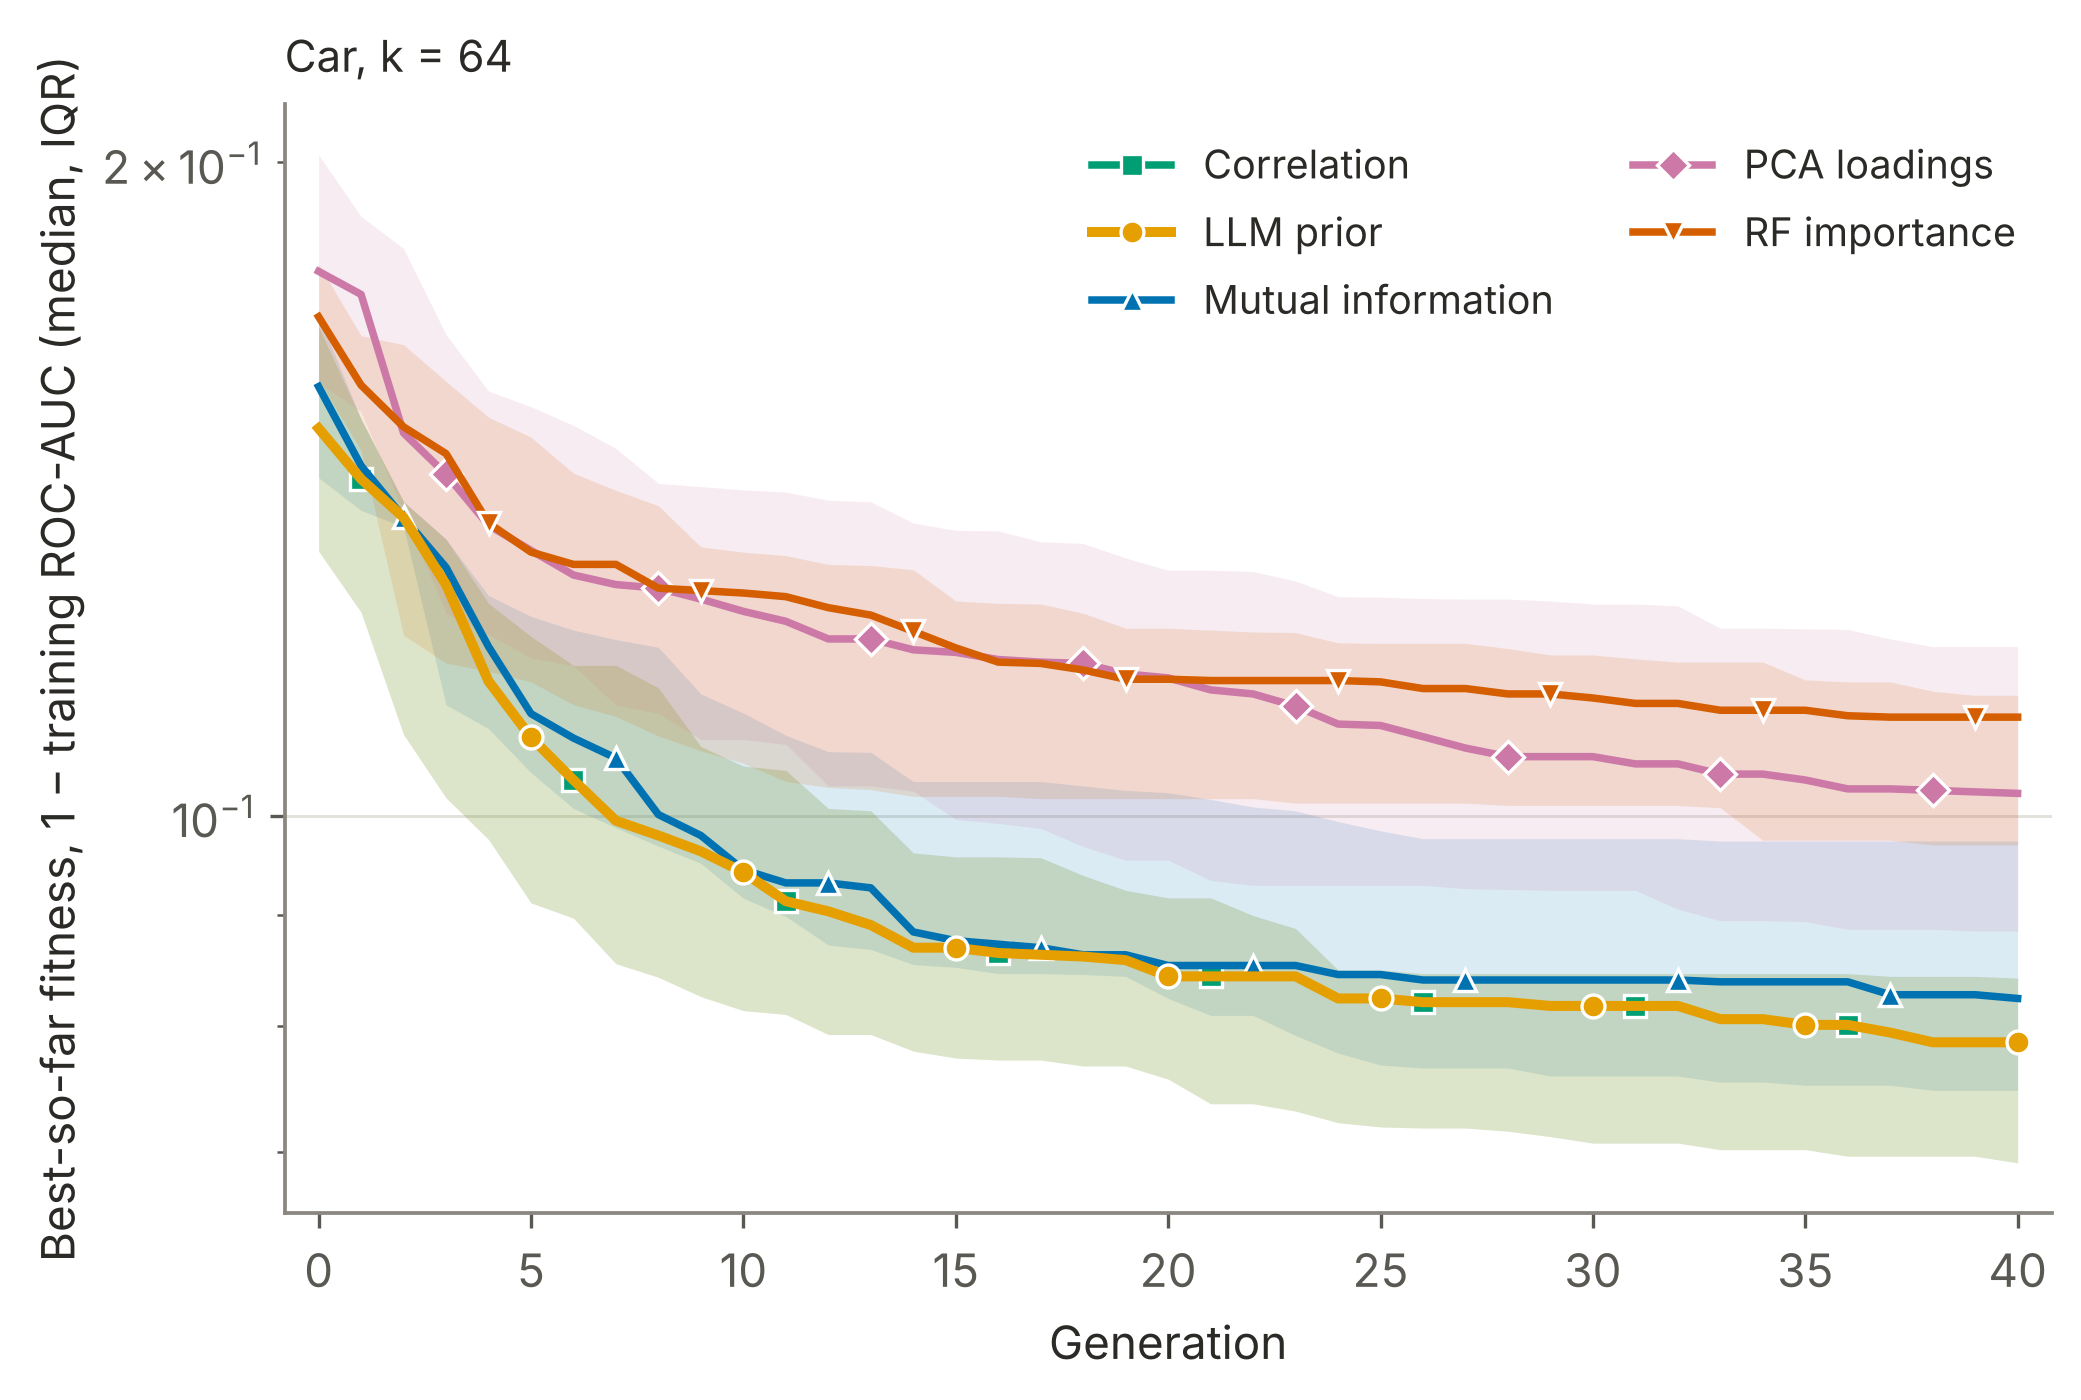

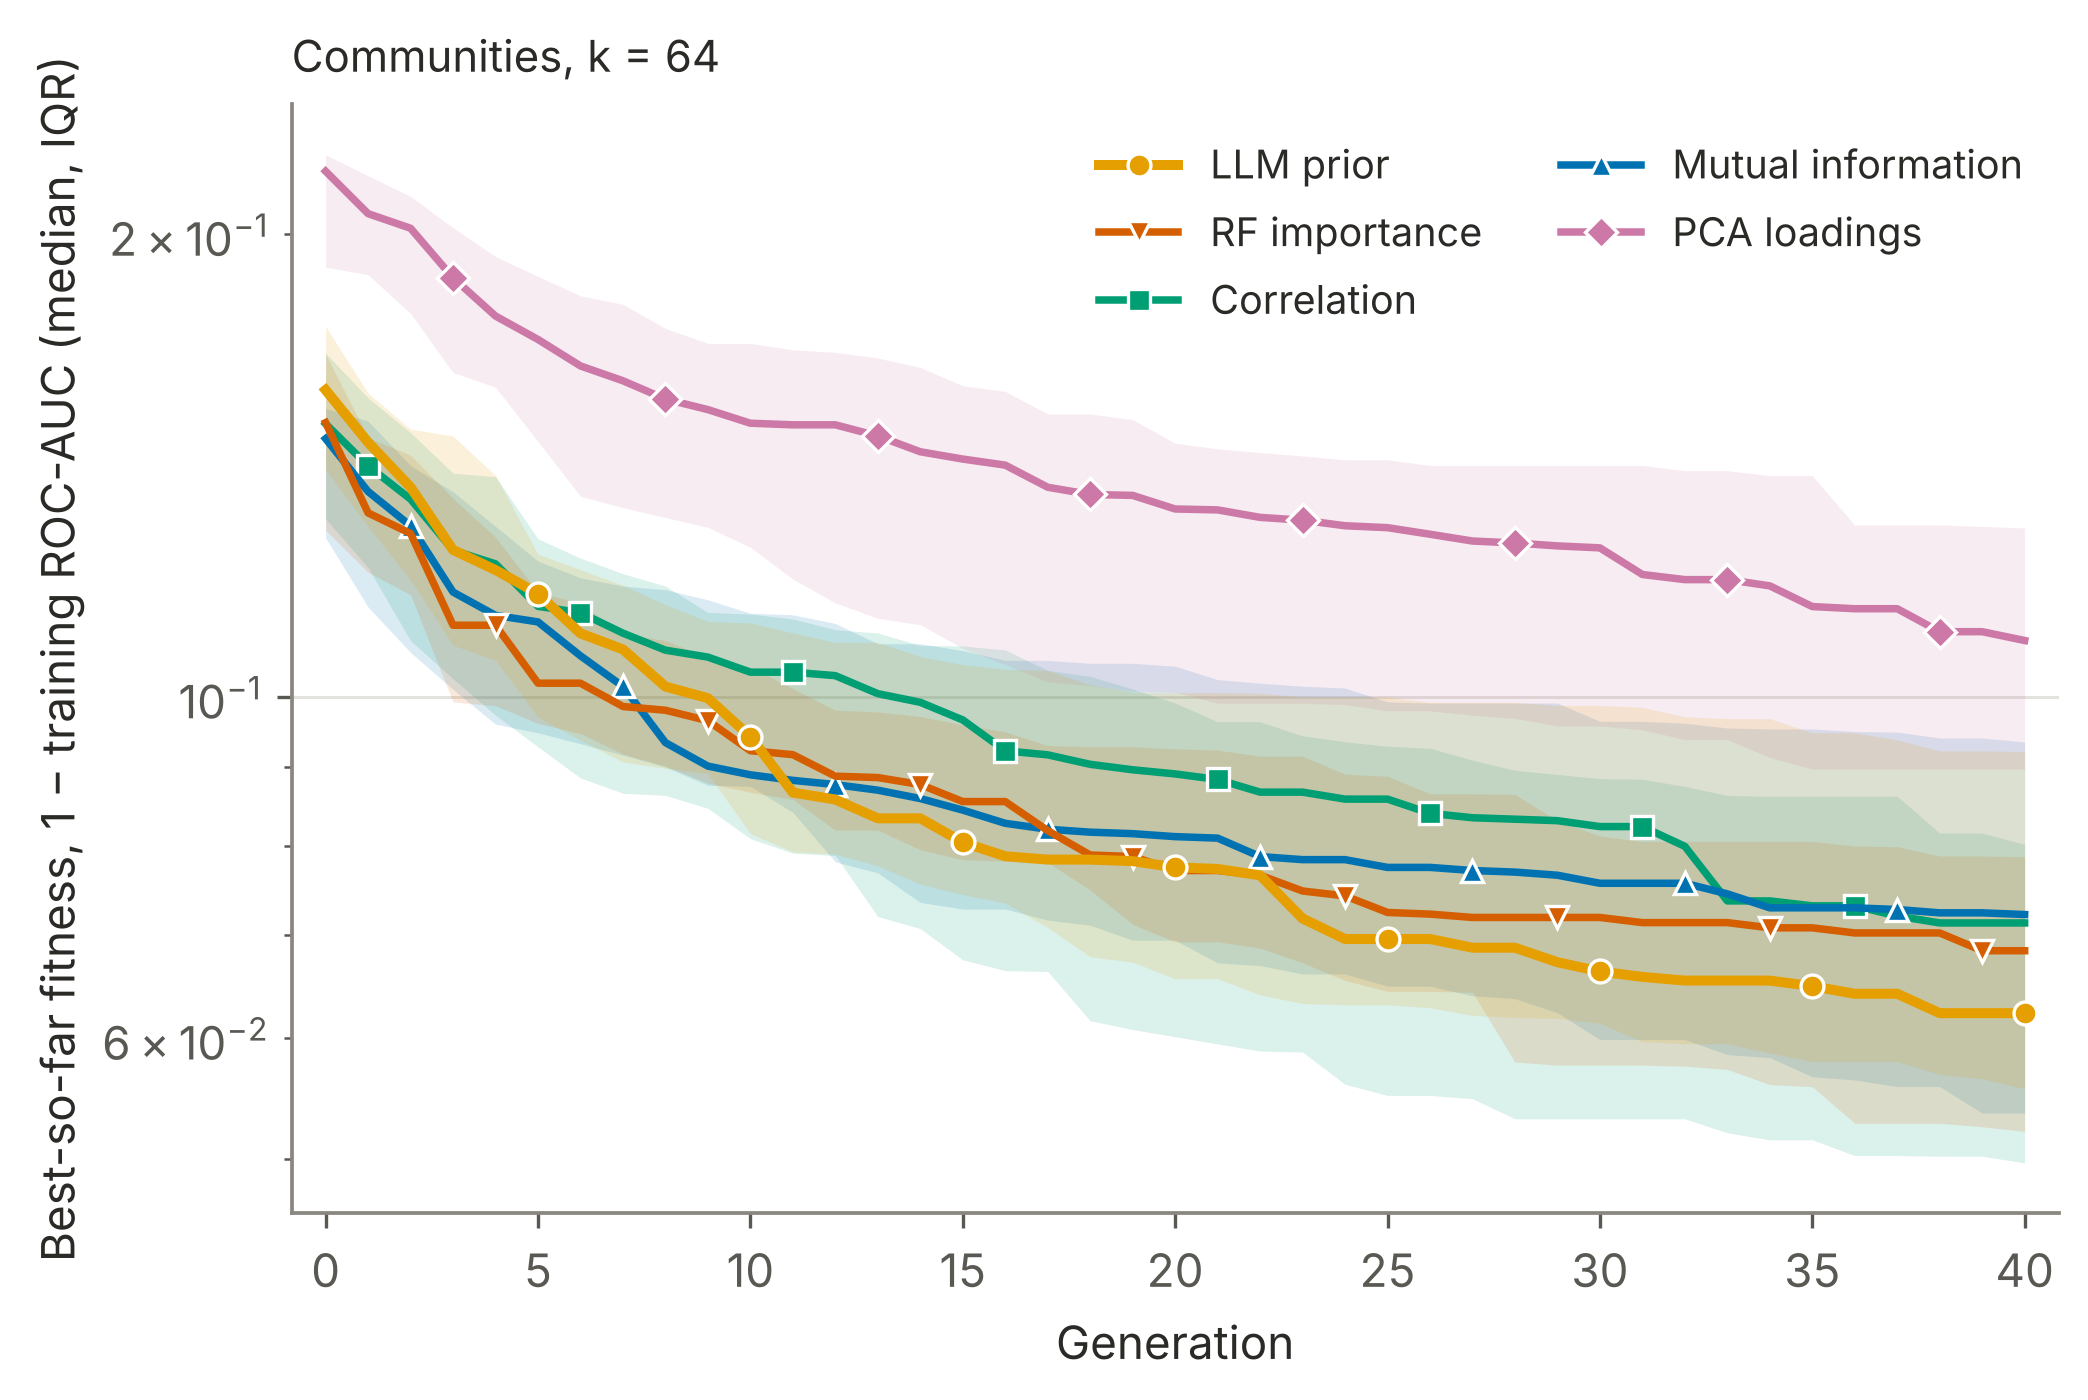

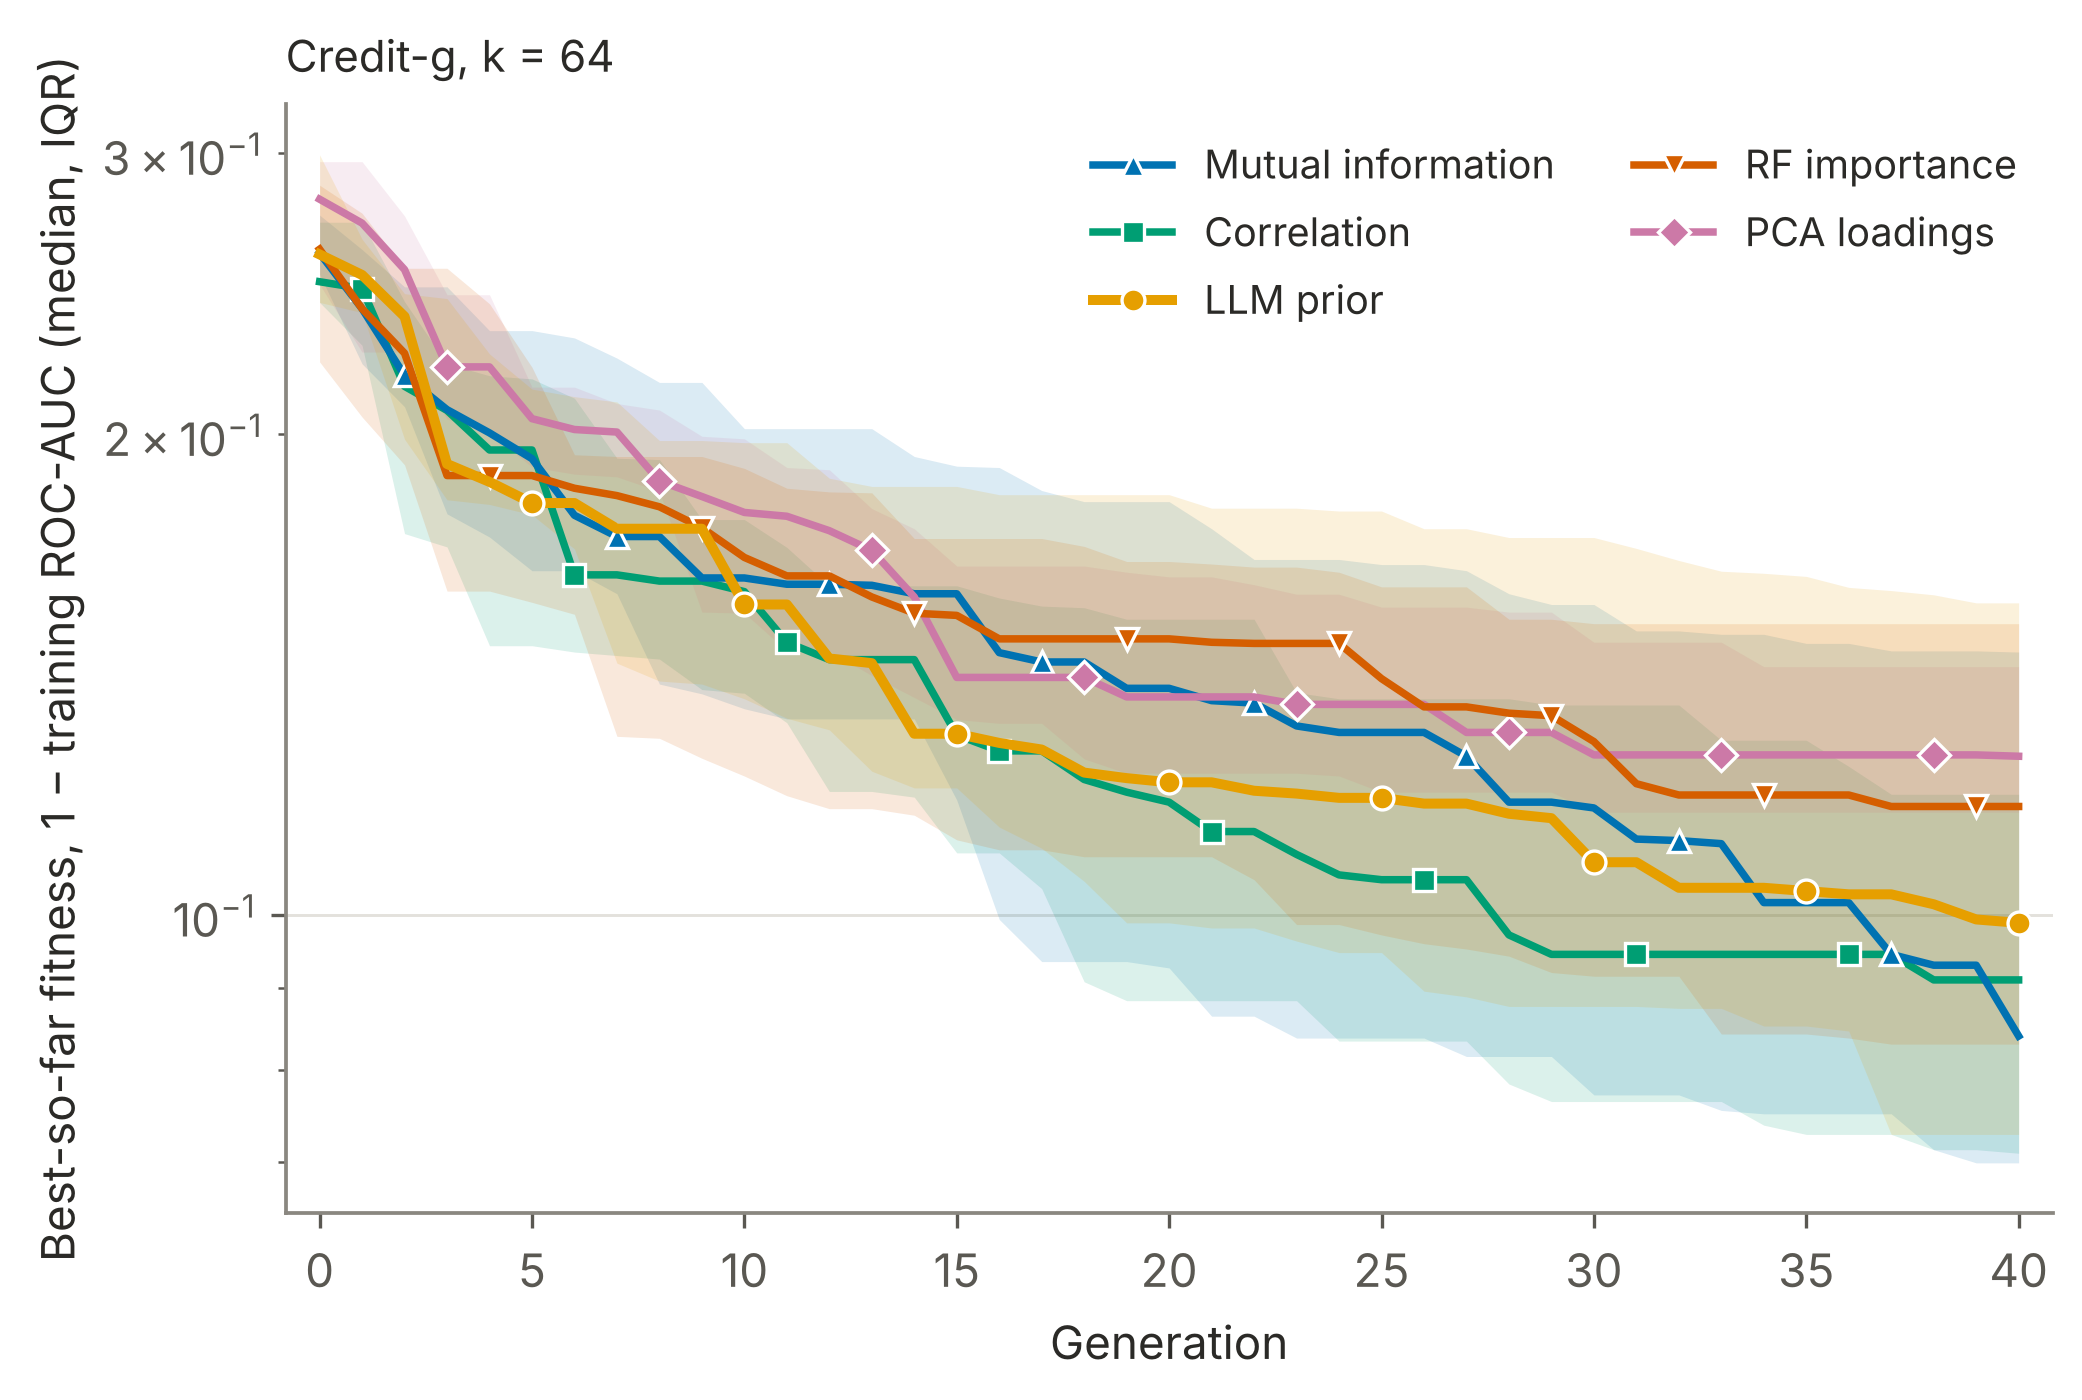

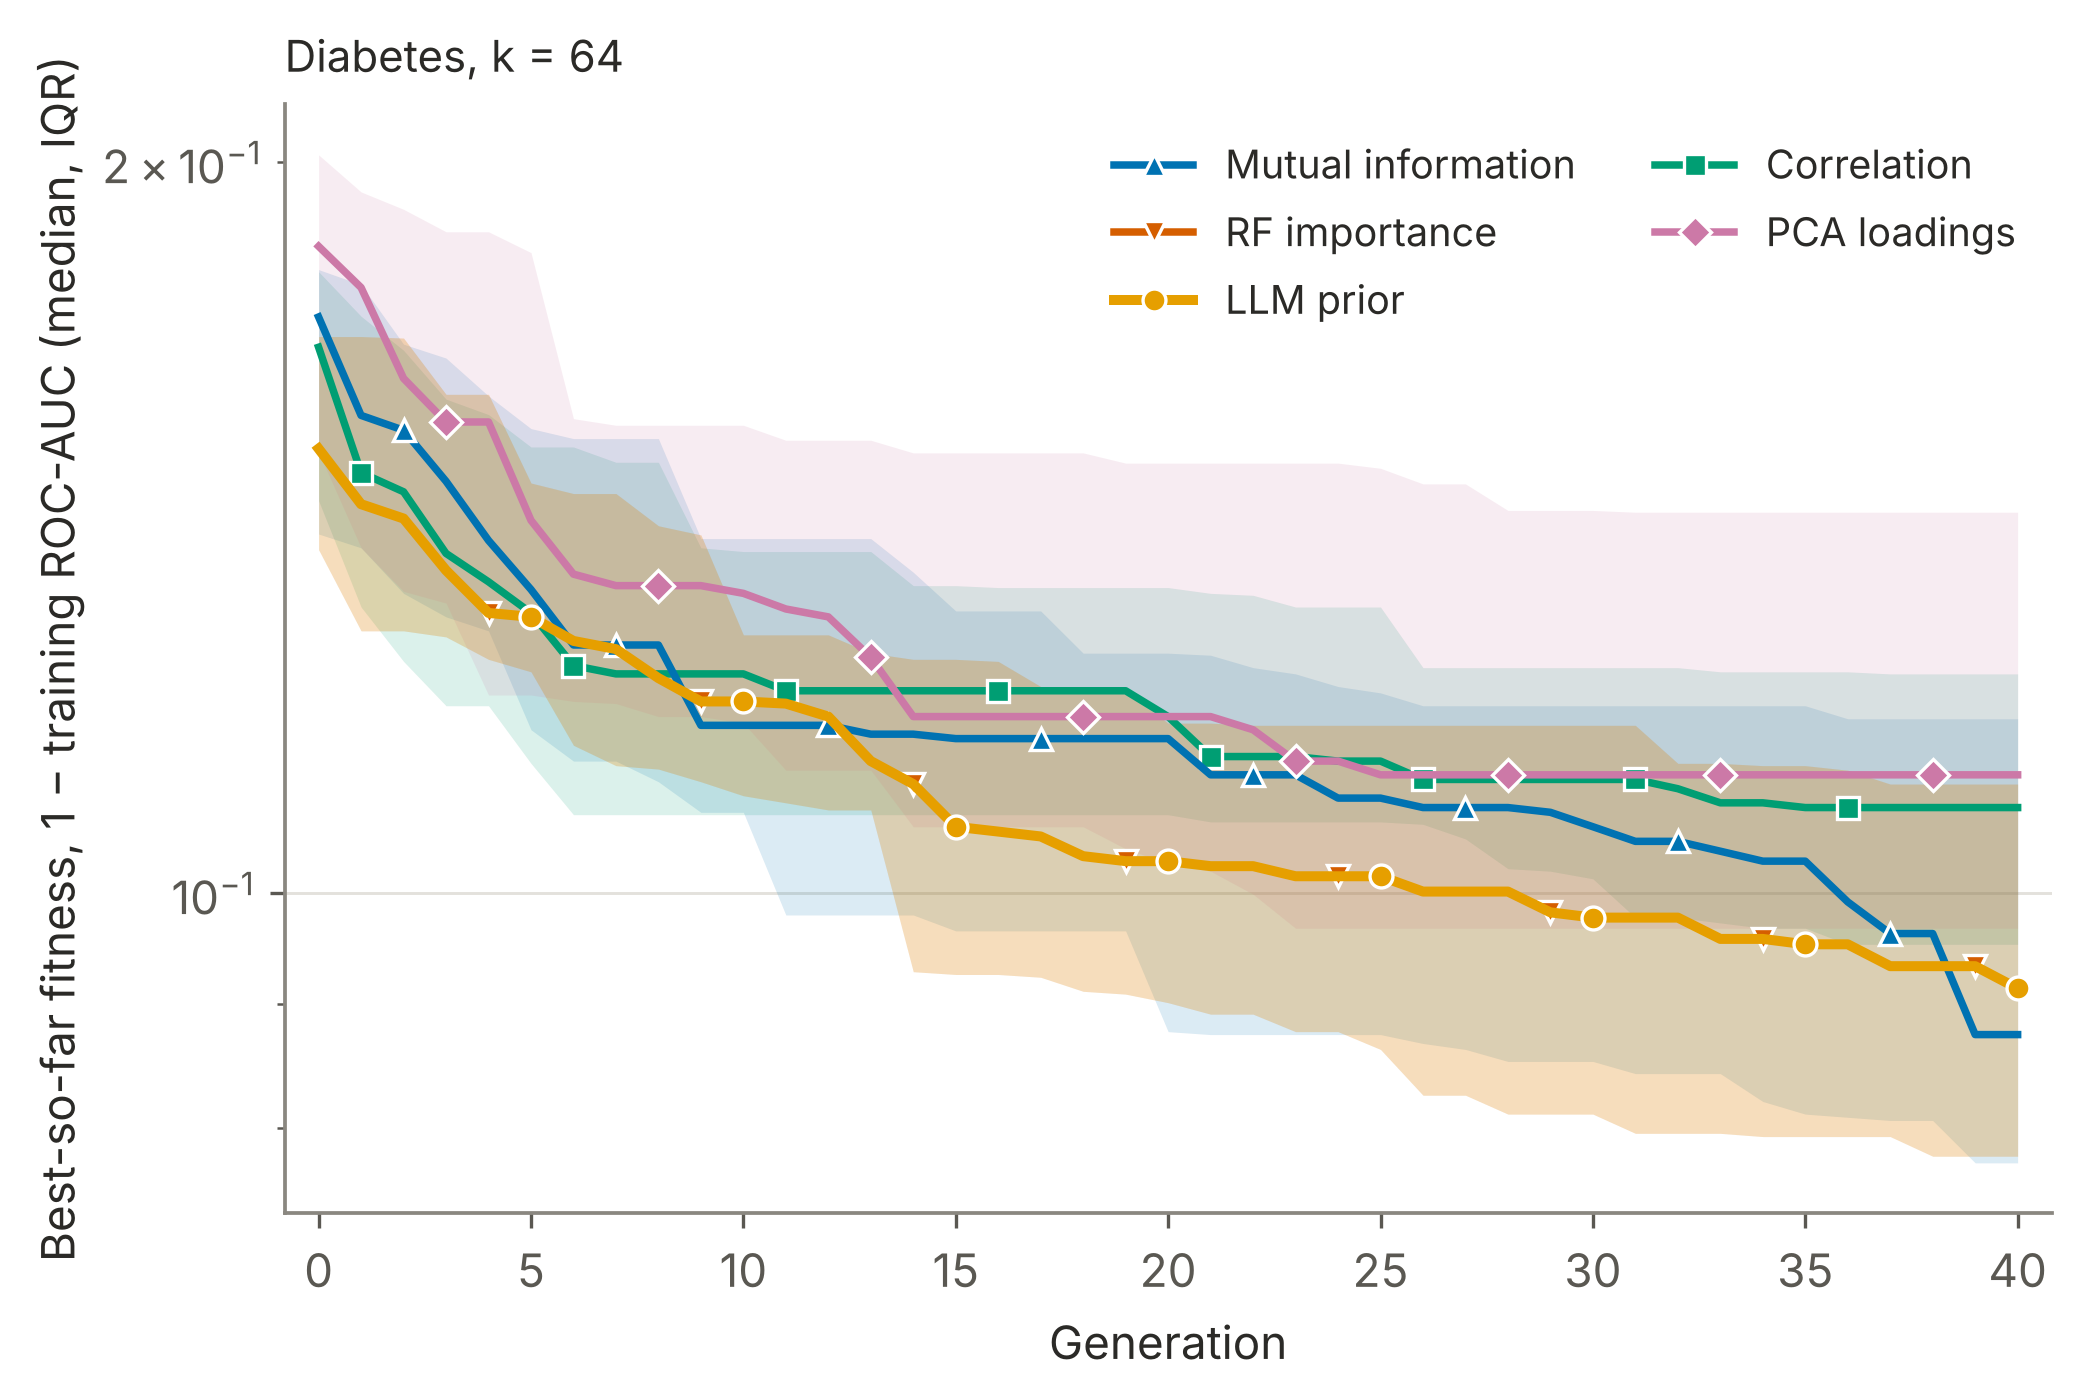

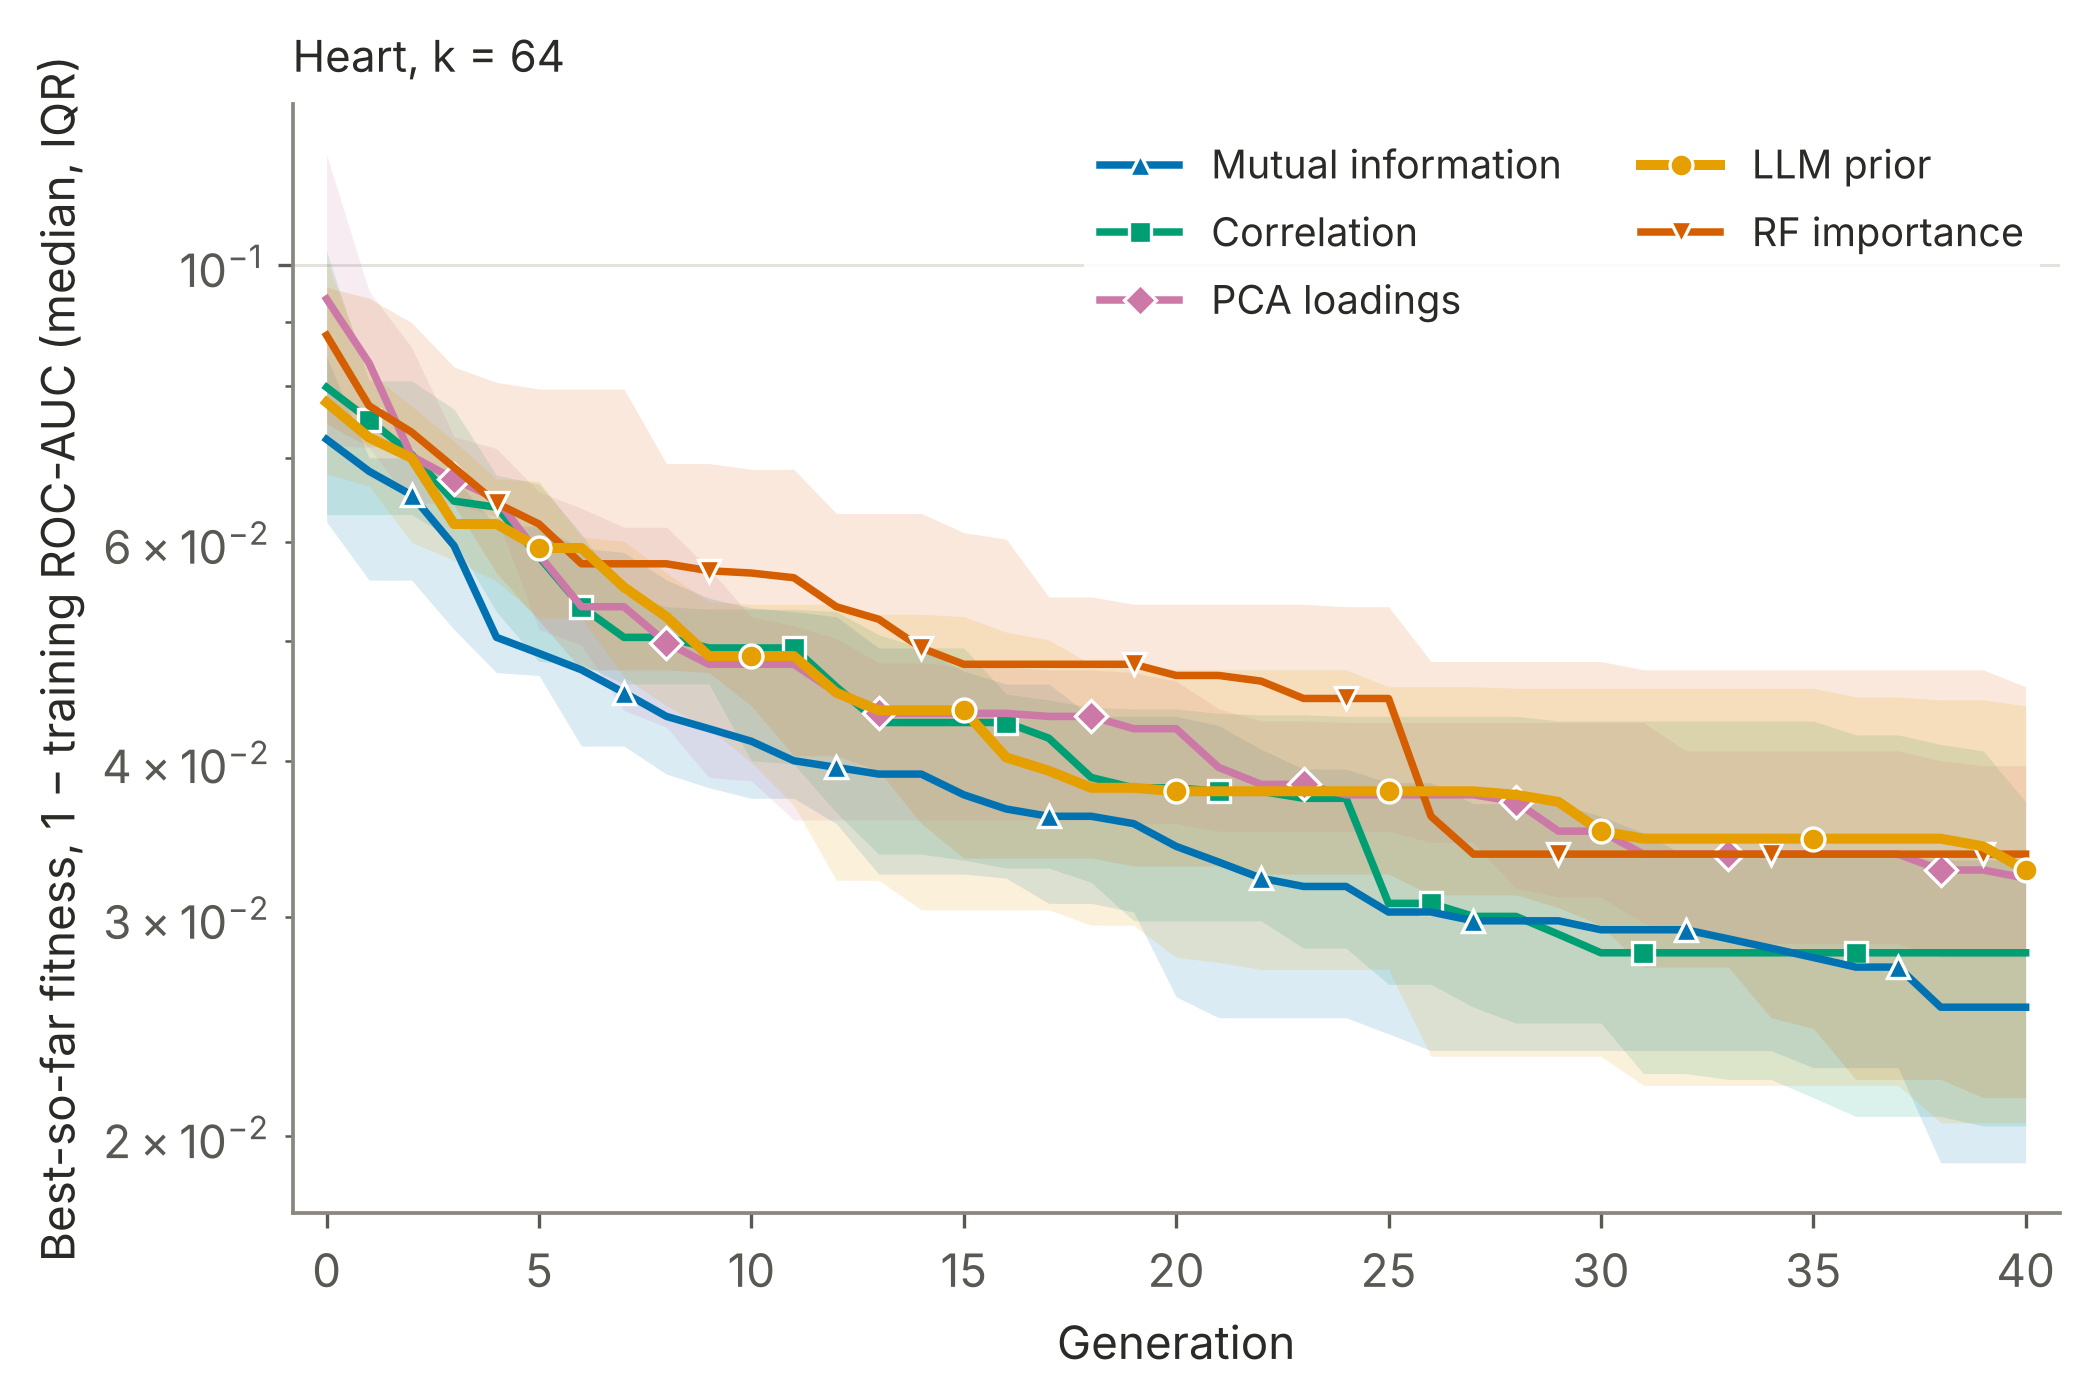

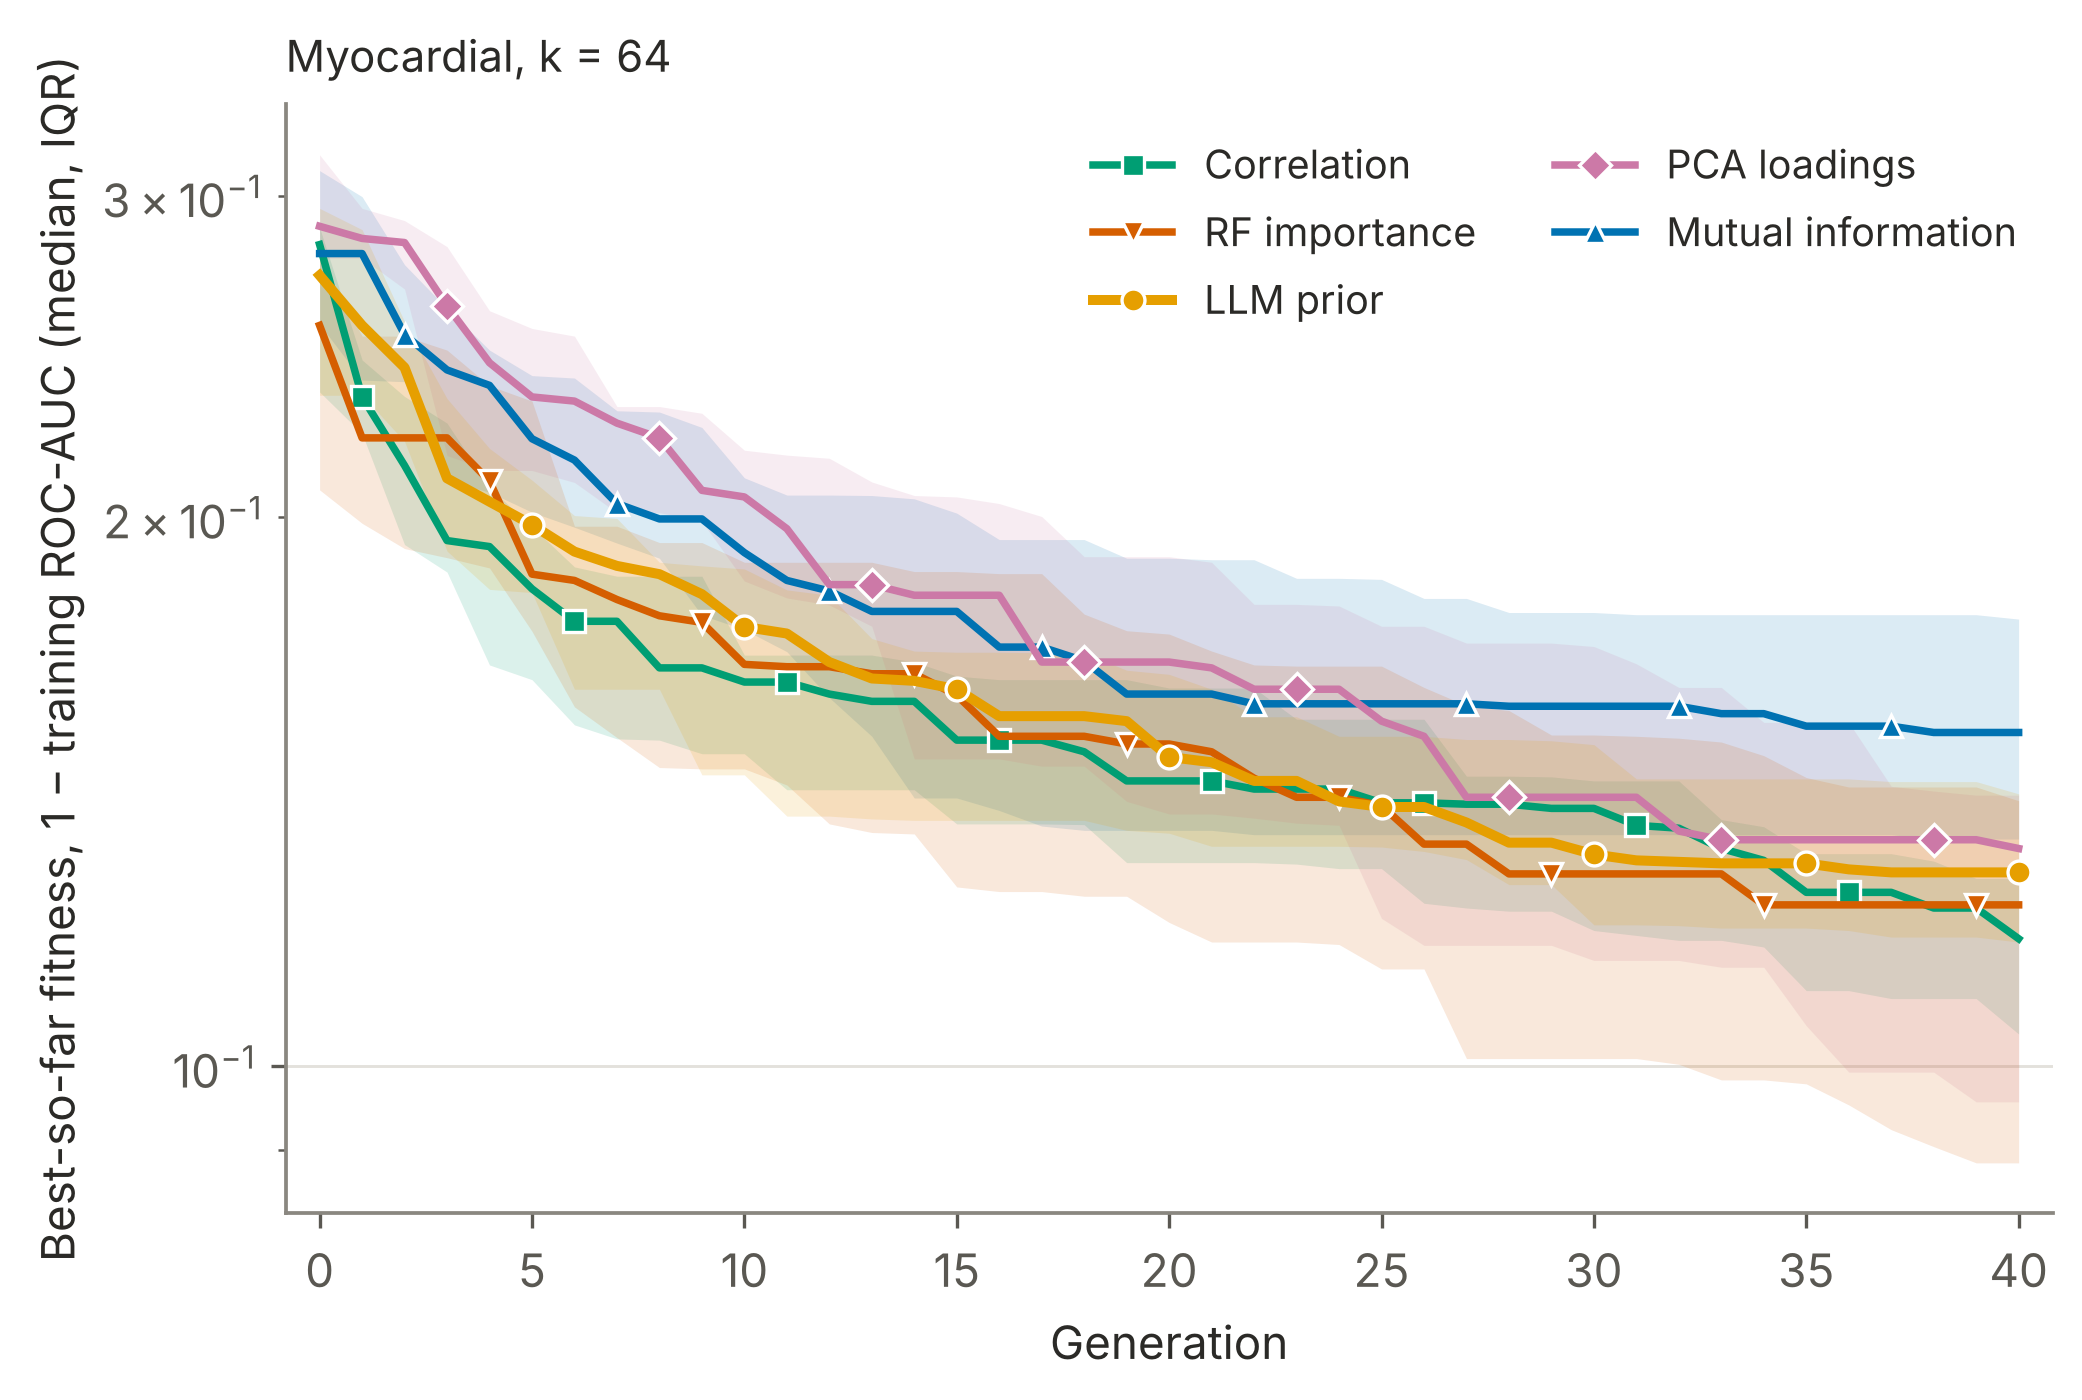

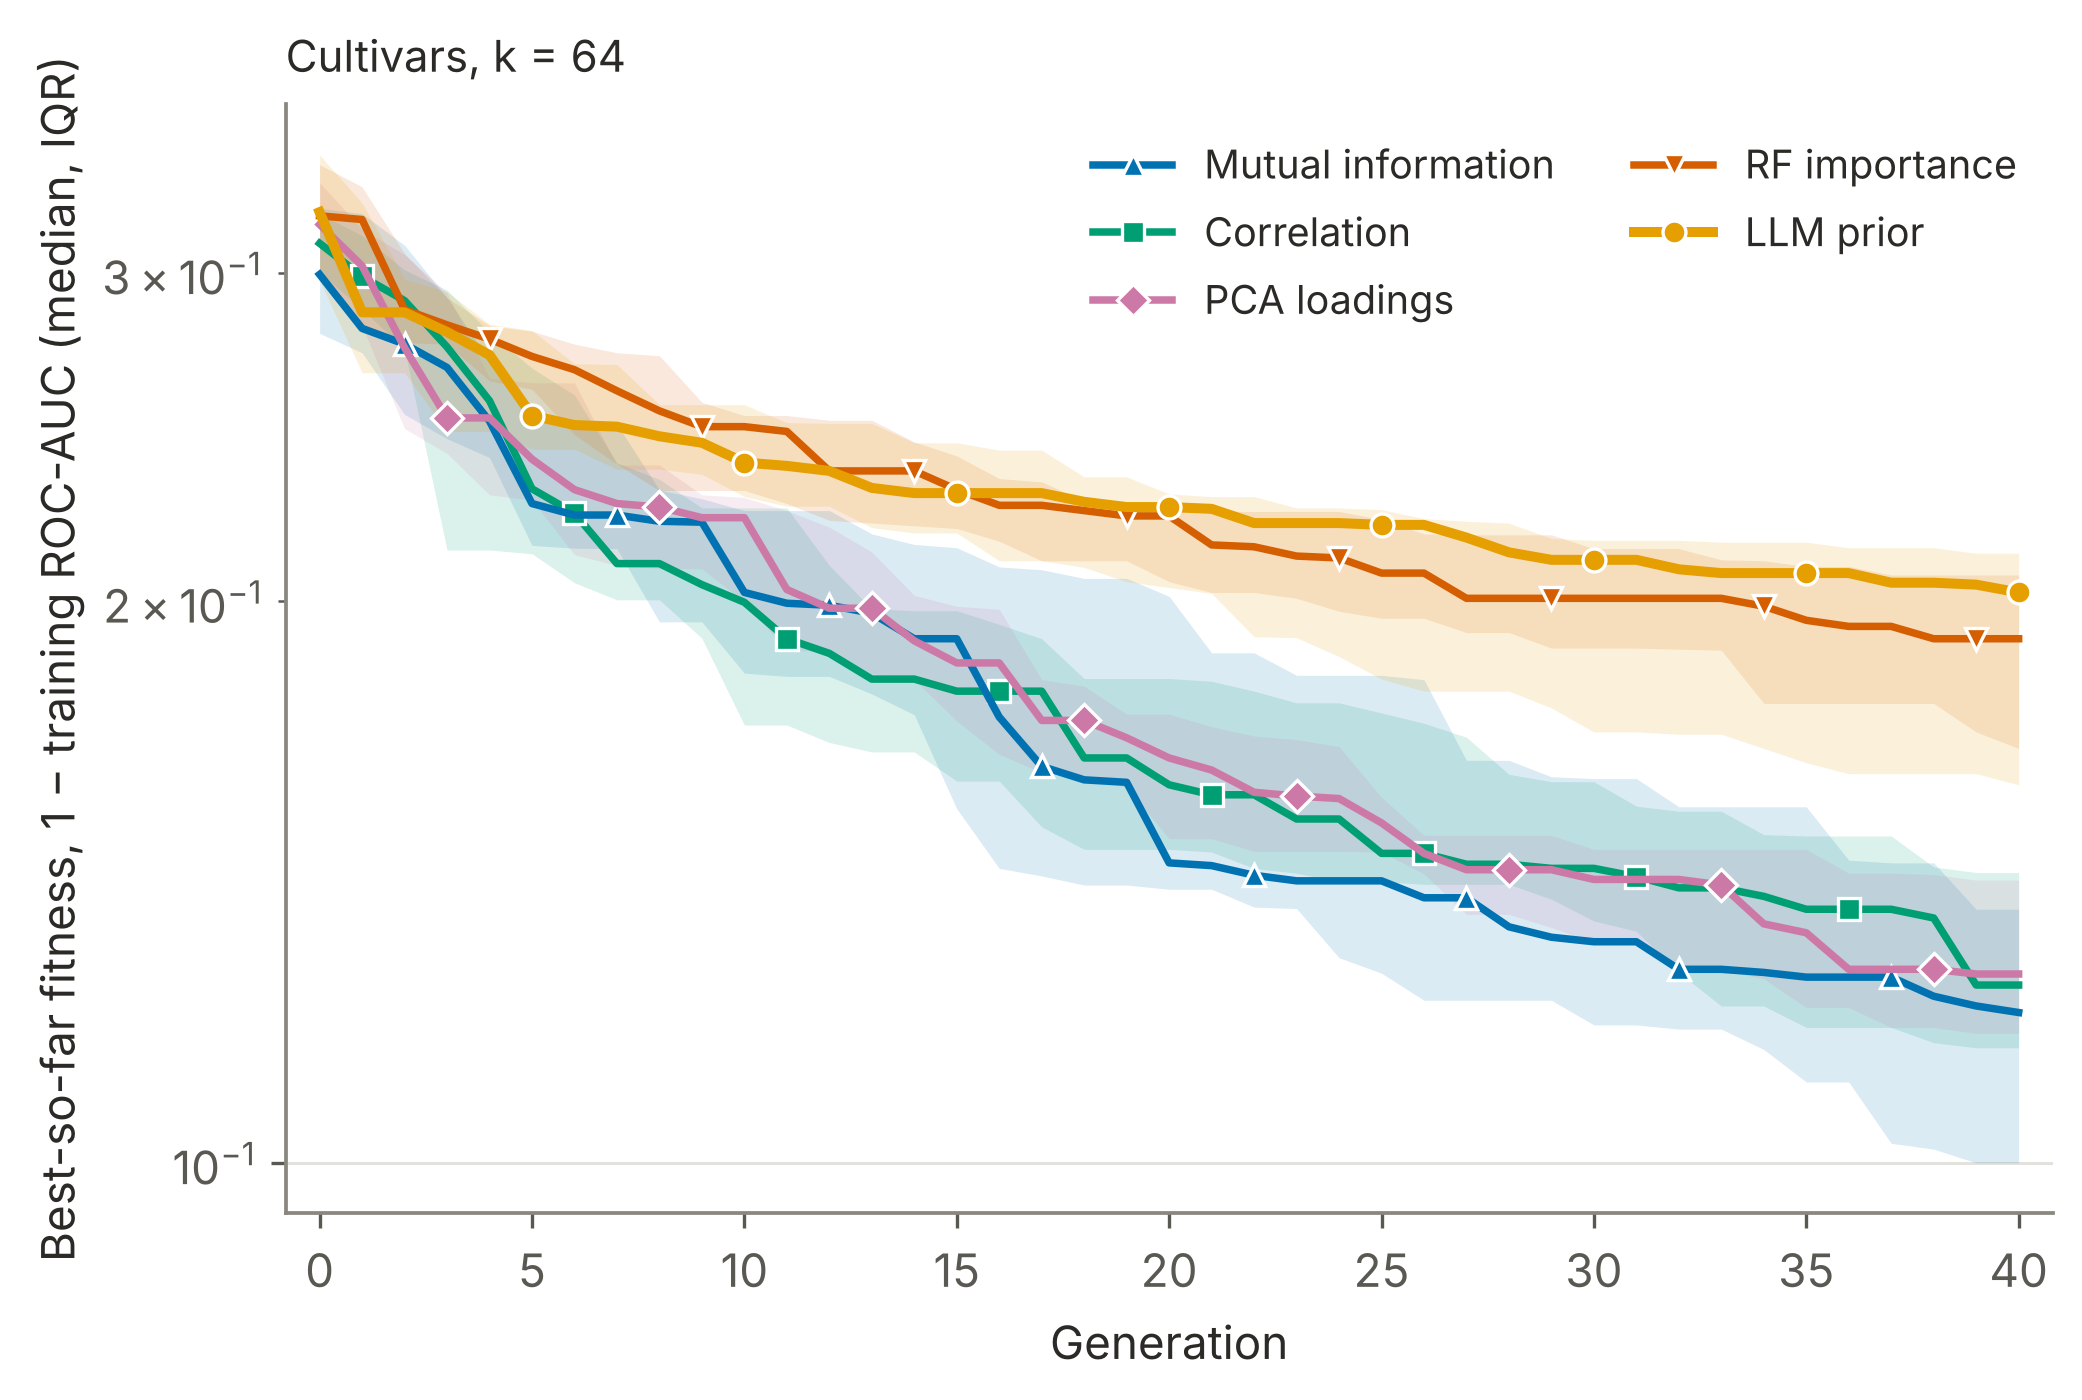

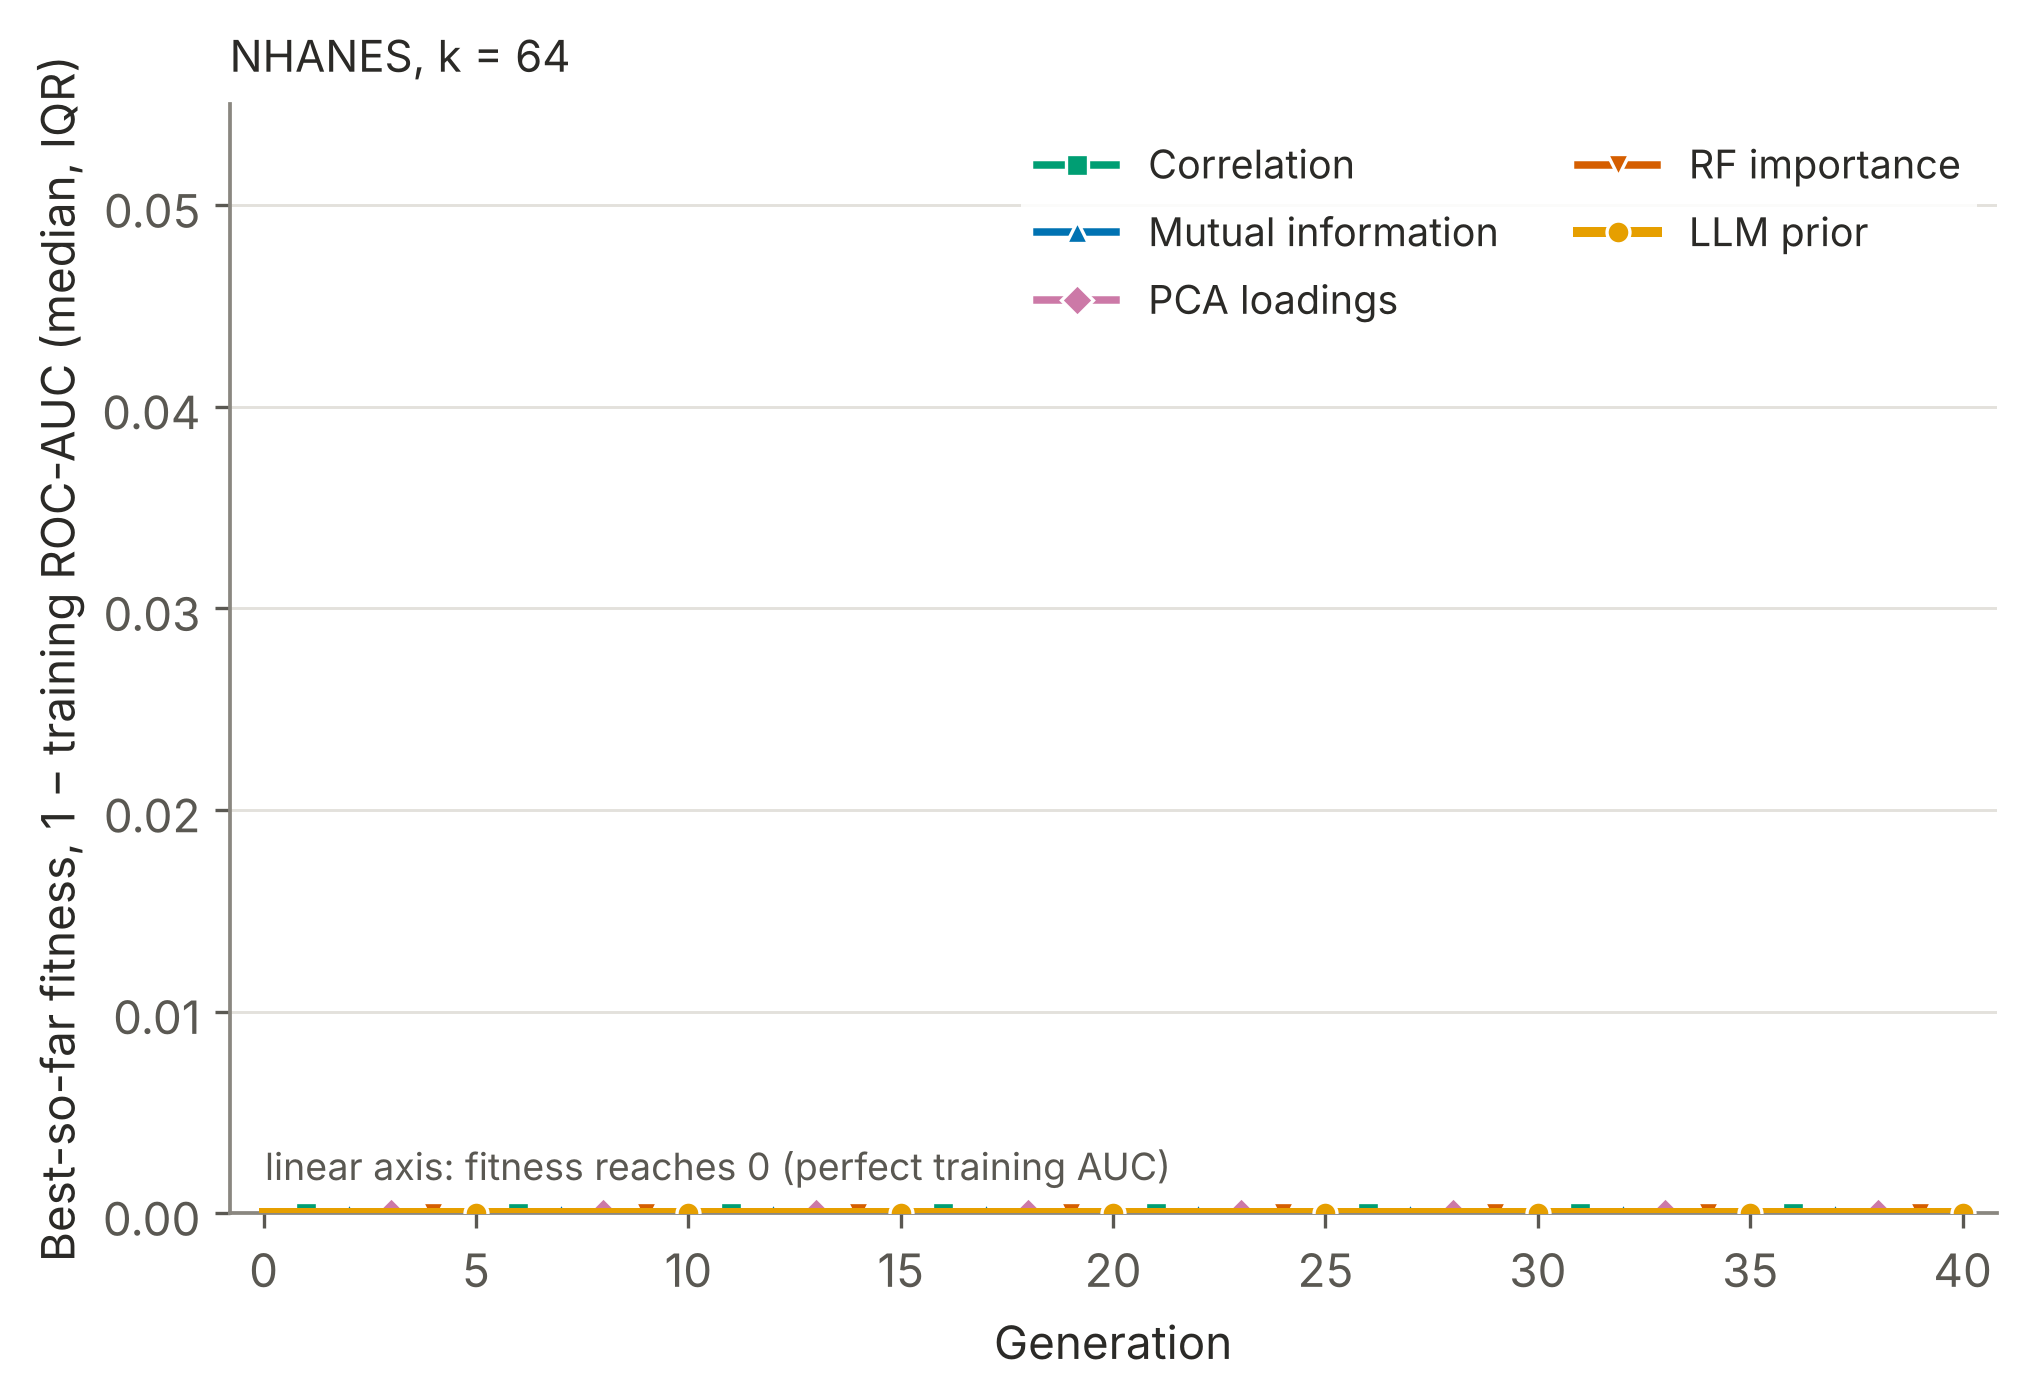

In [6]:
from IPython.display import Image, display

for dataset in DATASETS:
    display(Image(f"figures/fig_convergence_{dataset}_shot_{SHOT}.png", width=760))